In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("harmonized_fraud_dataset_5000.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (5000, 5)


,Time,Amount,TransactionType,FraudLabel,Source
0,86400.0,68.5,W,0,IEEE-CIS
1,86401.0,29.0,W,0,IEEE-CIS
2,86469.0,59.0,W,0,IEEE-CIS
3,86499.0,50.0,W,0,IEEE-CIS
4,86506.0,50.0,H,0,IEEE-CIS


In [35]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Find the fraud/target column automatically
possible_target_columns = ["Class", "class", "Fraud", "fraud", "fraud_label", "is_fraud"]

target_column = None

for col in possible_target_columns:
    if col in df.columns:
        target_column = col
        break

if target_column is None:
    print("\nTarget column not found automatically.")
    print("Available columns:", df.columns.tolist())
else:
    print(f"\nTarget column: {target_column}")

    print("\nClass distribution:")
    print(df[target_column].value_counts())

    print("\nClass percentages:")
    print(df[target_column].value_counts(normalize=True).mul(100).round(2))

    print("\nPercentage of fraud transactions:")
    print(round(df[target_column].mean() * 100, 2), "%")

Column names:
['Time', 'Amount', 'TransactionType', 'FraudLabel', 'Source']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Time             5000 non-null   float64
 1   Amount           5000 non-null   float64
 2   TransactionType  5000 non-null   object 
 3   FraudLabel       5000 non-null   int64  
 4   Source           5000 non-null   object 
dtypes: float64(2), int64(1), object(2)
memory usage: 195.4+ KB

Missing values:
0

Duplicate rows: 28

Target column not found automatically.
Available columns: ['Time', 'Amount', 'TransactionType', 'FraudLabel', 'Source']


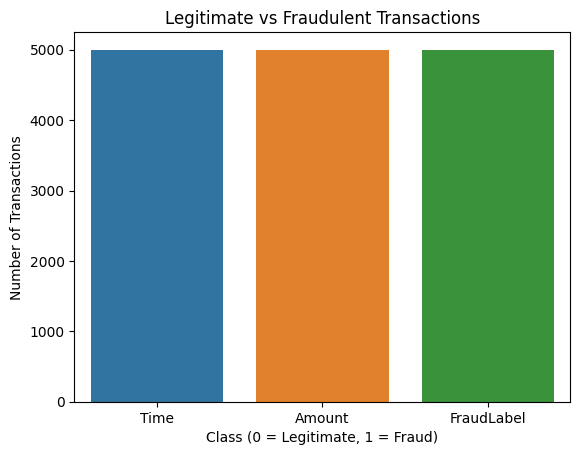

In [36]:

import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
sns.countplot(data=df, x=target_column)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Detect the target column
if "Class" in df.columns:
    target_column = "Class"
elif "FraudLabel" in df.columns:
    target_column = "FraudLabel"
elif "fraud_label" in df.columns:
    target_column = "fraud_label"
elif "is_fraud" in df.columns:
    target_column = "is_fraud"
elif "Fraud" in df.columns:
    target_column = "Fraud"
elif "fraud" in df.columns:
    target_column = "fraud"
else:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

# Remove rows with missing target labels
df = df.dropna(subset=[target_column]).copy()

# Separate features and target
X = df.drop(columns=[target_column])
y = df[target_column].astype(int)

# Remove non-numeric columns for this numeric ML model
X = X.select_dtypes(include=["number"]).copy()

# Handle missing and infinite feature values
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scale available Time and Amount columns
scaler = StandardScaler()
scale_columns = [
    col for col in ["Time", "Amount"]
    if col in X_train.columns
]

if scale_columns:
    X_train.loc[:, scale_columns] = scaler.fit_transform(
        X_train[scale_columns]
    )
    X_test.loc[:, scale_columns] = scaler.transform(
        X_test[scale_columns]
    )

print("Target column:", target_column)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nFraud cases in training:", int((y_train == 1).sum()))
print("Fraud cases in testing:", int((y_test == 1).sum()))

print("\nFeatures used:", X_train.columns.tolist())

Target column: FraudLabel
Training rows: 4000
Testing rows: 1000

Training class distribution:
FraudLabel
0    2000
1    2000
Name: count, dtype: int64

Testing class distribution:
FraudLabel
0    500
1    500
Name: count, dtype: int64

Fraud cases in training: 2000
Fraud cases in testing: 500

Features used: ['Time', 'Amount']


In [38]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [39]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("Average precision:", average_precision_score(y_test, y_prob))

              precision    recall  f1-score   support

  Legitimate       0.74      0.97      0.84       500
       Fraud       0.95      0.66      0.78       500

    accuracy                           0.81      1000
   macro avg       0.85      0.81      0.81      1000
weighted avg       0.85      0.81      0.81      1000

Precision: 0.953757225433526
Recall: 0.66
F1-score: 0.7801418439716312
Average precision: 0.8671673537503264


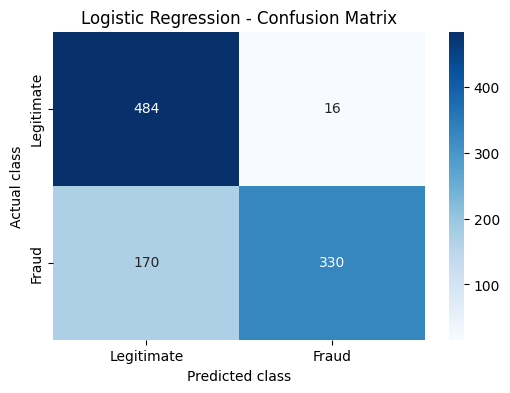

In [40]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [41]:

from sklearn.linear_model import LogisticRegression

# Create and train the model
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("Model training completed successfully!")


Model training completed successfully!


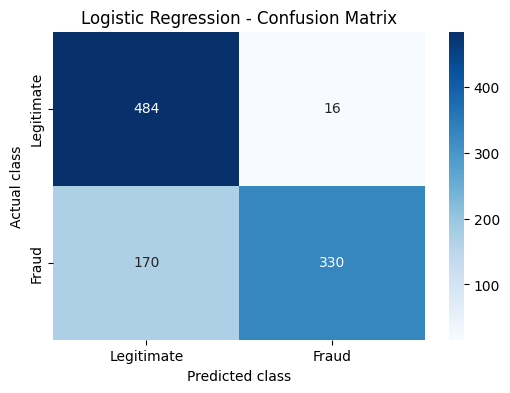

In [42]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [43]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Fraud Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Fraud Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("Fraud F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))


Accuracy: 0.814
Fraud Precision: 0.9538
Fraud Recall: 0.66
Fraud F1-Score: 0.7801

Classification Report:

              precision    recall  f1-score   support

  Legitimate       0.74      0.97      0.84       500
       Fraud       0.95      0.66      0.78       500

    accuracy                           0.81      1000
   macro avg       0.85      0.81      0.81      1000
weighted avg       0.85      0.81      0.81      1000



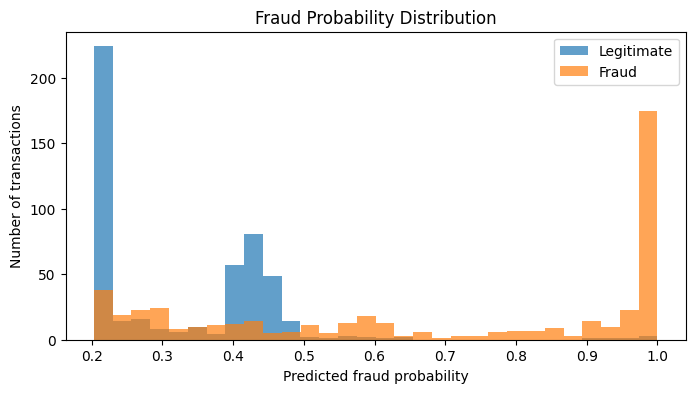

In [44]:

import numpy as np

# Probability of class 1 (fraud)
y_prob = model.predict_proba(X_test)[:, 1]

plt.figure(figsize=(8, 4))
plt.hist(y_prob[y_test == 0], bins=30, alpha=0.7, label="Legitimate")
plt.hist(y_prob[y_test == 1], bins=30, alpha=0.7, label="Fraud")

plt.xlabel("Predicted fraud probability")
plt.ylabel("Number of transactions")
plt.title("Fraud Probability Distribution")
plt.legend()
plt.show()


In [45]:

import joblib

joblib.dump(model, "fraud_detection_model.pkl")
joblib.dump(scaler, "fraud_scaler.pkl")
joblib.dump(list(X_train.columns), "fraud_feature_columns.pkl")

print("Model and preprocessing files saved!")


Model and preprocessing files saved!


In [46]:

from google.colab import files

files.download("fraud_detection_model.pkl")
files.download("fraud_scaler.pkl")
files.download("fraud_feature_columns.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:

!pip install -q gradio joblib


In [48]:

import joblib
import pandas as pd
import numpy as np

model = joblib.load("fraud_detection_model.pkl")
scaler = joblib.load("fraud_scaler.pkl")
feature_columns = joblib.load("fraud_feature_columns.pkl")

print("Model loaded successfully!")
print("Number of features:", len(feature_columns))
print("Features:", feature_columns)


Model loaded successfully!
Number of features: 2
Features: ['Time', 'Amount']


In [49]:

# Create sample transactions from the test data
sample_transactions = X_test.head(10).copy()

print("Sample transactions available:", len(sample_transactions))
display(sample_transactions.head())


Sample transactions available: 10


,Time,Amount
2217,-0.595250,-0.253813
4281,-0.595818,1.460437
2443,-0.594379,-0.253844
4174,-0.595872,-0.253731
2922,0.129008,-0.253855


In [50]:

import gradio as gr

def predict_fraud(sample_index):
    index = int(sample_index)
    transaction = sample_transactions.iloc[[index]].copy()

    prediction = int(model.predict(transaction)[0])
    probability = float(model.predict_proba(transaction)[0][1])

    result = "FRAUDULENT TRANSACTION" if prediction == 1 else "LEGITIMATE TRANSACTION"

    return result, f"{probability * 100:.2f}%"

demo = gr.Interface(
    fn=predict_fraud,
    inputs=gr.Dropdown(
        choices=[str(i) for i in range(len(sample_transactions))],
        value="0",
        label="Select a sample transaction"
    ),
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Fraud probability")
    ],
    title="Credit Card Fraud Detection",
    description="Select a sample transaction to see the trained model's prediction."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://182887209b26bf35f6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [51]:

print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())


Dataset columns:
['Time', 'Amount', 'TransactionType', 'FraudLabel', 'Source']

First 5 rows:


,Time,Amount,TransactionType,FraudLabel,Source
0,86400.0,68.5,W,0,IEEE-CIS
1,86401.0,29.0,W,0,IEEE-CIS
2,86469.0,59.0,W,0,IEEE-CIS
3,86499.0,50.0,W,0,IEEE-CIS
4,86506.0,50.0,H,0,IEEE-CIS


In [52]:

import gradio as gr
import pandas as pd
import numpy as np

# Use the exact features used during model training
feature_columns = list(X_train.columns)

print("Model expects these features:", feature_columns)


Model expects these features: ['Time', 'Amount']


In [53]:

def predict_transaction(amount, transaction_type, time_value):
    try:
        amount = float(amount)
        time_value = float(time_value)

        if amount < 0 or time_value < 0:
            return "Invalid input", "Amount and time must be non-negative."

        # Start with default values for the model's features
        input_data = {col: 0.0 for col in feature_columns}

        if "Amount" in input_data:
            input_data["Amount"] = amount

        if "Time" in input_data:
            input_data["Time"] = time_value

        # This dataset uses W/H/etc. for transaction type.
        # Only use the field if the model was trained with encoded type features.
        if "TransactionType" in input_data:
            input_data["TransactionType"] = transaction_type

        transaction = pd.DataFrame([input_data], columns=feature_columns)

        # Apply the same scaler used during training
        scale_columns = [
            col for col in ["Time", "Amount"]
            if col in feature_columns
        ]

        if scale_columns:
            transaction.loc[:, scale_columns] = scaler.transform(
                transaction[scale_columns]
            )

        prediction = int(model.predict(transaction)[0])
        probability = float(model.predict_proba(transaction)[0][1])

        result = (
            "⚠️ Potential Fraud"
            if prediction == 1
            else "✅ Likely Legitimate"
        )

        return result, f"{probability * 100:.2f}%"

    except Exception as e:
        return "Prediction error", str(e)


In [60]:

import gradio as gr

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        """
        # 🛡️ Credit Card Fraud Detection
        ### AI-powered Transaction Risk Analyzer

        Enter the transaction details and click **Analyze Transaction**
        to see the model's prediction.
        """
    )

    with gr.Row():
        with gr.Column():
            gr.Markdown("### 💳 Transaction Details")

            amount = gr.Number(
                label="Transaction Amount",
                value=000,
                minimum=0,
                info="Enter the transaction amount."
            )

            transaction_type = gr.Dropdown(
                choices=[
                    "W", "H", "C", "R", "S",
                    "CardTransaction", "CASH_OUT", "CASH_IN",
                    "TRANSFER", "PAYMENT", "DEBIT"
                ],
                value="CardTransaction",
                label="Transaction Type",
                info="Choose a category present in the dataset."
            )

            time_value = gr.Number(
                label="Transaction Time",
                value=000,
                minimum=0,
                info="Enter the Time value used by your dataset."
            )

            analyze_button = gr.Button(
                "🔍 Analyze Transaction",
                variant="primary"
            )

        with gr.Column():
            gr.Markdown("### 📊 Analysis Result")

            prediction_output = gr.Textbox(
                label="Fraud Detection Result",
                placeholder="Your prediction will appear here...",
                interactive=False
            )

            fraud_score_output = gr.Textbox(
                label="Model Fraud Probability",
                placeholder="Fraud probability will appear here...",
                interactive=False
            )

            gr.Markdown(
                """
                **How to interpret the result**

                - **Potential Fraud:** The model predicts the fraud class.
                - **Likely Legitimate:** The model predicts the legitimate class.
                - **Fraud Probability:** The model's estimated probability,
                  not a guarantee that the transaction is fraudulent.
                """
            )

    analyze_button.click(
        fn=predict_transaction,
        inputs=[amount, transaction_type, time_value],
        outputs=[prediction_output, fraud_score_output]
    )

    gr.Markdown(
        """
        ---
        ⚠️ **Educational Demo:** This model is for learning purposes only.
        It should not be used to approve or reject real financial transactions.
        """
    )

demo.launch(share=True)


/tmp/ipykernel_625/3882599231.py:3: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3fb7e50908fd020356.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
